In [1]:
%%bash
pip install -q ultralytics huggingface_hub

In [2]:
from huggingface_hub import hf_hub_download
from ultralytics import YOLO

# Download the model file from Hugging Face
model_path = hf_hub_download(repo_id="ZubairAli25266/ppe_detector", filename="best.pt")

# Load the YOLOv8 model
model = YOLO(model_path)
print("Model loaded successfully!")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


best.pt: reconstructing file:   0%|          |  0.00B / 6.51MB            

best.pt: downloading bytes:           |  0.00B            

Model loaded successfully!


In [3]:
import gdown

# Google Drive file link provided by the user
shareable_link = 'https://drive.google.com/file/d/14yQh3XXkCZyJlh9scGH5nCgX1tOXhJ4R/view?usp=sharing'

# Extract the file ID and download using gdown
file_id = shareable_link.split('/d/')[1].split('/')[0]
download_url = f'https://drive.google.com/uc?id={file_id}'

# Set the path where the downloaded zip should be saved
zip_path = 'ppe_dataset.zip'

gdown.download(download_url, zip_path, quiet=False)
print("Downloaded dataset archive to:", zip_path)

# Extract the dataset archive into Colab's working directory.
from pathlib import Path
import zipfile

extract_dir = Path("/content/ppe_data")

# Unpack the dataset files.
with zipfile.ZipFile(zip_path, "r") as archive:
    archive.extractall(extract_dir)

# Find the dataset configuration file.
yaml_files = list(extract_dir.rglob("data.yaml"))

# Stop if the expected configuration file is missing.
if not yaml_files:
    raise FileNotFoundError(
        "No data.yaml found. Check the structure of your dataset ZIP."
    )

data_yaml = yaml_files[0]
print("Dataset configuration:", data_yaml)

# Inspect the extracted folder structure to verify train/val/test subfolder names
import os
dataset_root = "/content/ppe_data/Dataset_no_person_glasses"
if os.path.exists(dataset_root):
    print("Subdirectories inside dataset root:", os.listdir(dataset_root))
    for sub in os.listdir(dataset_root):
        sub_path = os.path.join(dataset_root, sub)
        if os.path.isdir(sub_path):
            print(f"  {sub}/ contents:", os.listdir(sub_path)[:5])
else:
    print(f"Directory {dataset_root} does not exist. Checked /content/ppe_data:", os.listdir("/content/ppe_data"))




Downloading...
From (original): https://drive.google.com/uc?id=14yQh3XXkCZyJlh9scGH5nCgX1tOXhJ4R
From (redirected): https://drive.google.com/uc?id=14yQh3XXkCZyJlh9scGH5nCgX1tOXhJ4R&confirm=t&uuid=a89acc56-edbb-4982-a81d-eee7ac5aa27e
To: /content/ppe_dataset.zip
100%|██████████| 614M/614M [00:09<00:00, 66.7MB/s]


Downloaded dataset archive to: ppe_dataset.zip
Dataset configuration: /content/ppe_data/Dataset_no_person_glasses/data.yaml
Subdirectories inside dataset root: ['test', 'data.yaml', 'train', 'val']
  test/ contents: ['images', 'labels']
  train/ contents: ['images', 'labels']
  val/ contents: ['images', 'labels']


In [7]:
import yaml

# Path to the data.yaml file
yaml_path = '/content/ppe_data/Dataset_no_person_glasses/data.yaml'

# Load the configuration
with open(yaml_path, 'r') as f:
    data_config = yaml.safe_load(f)

# Update dataset base path and subfolder structures for Google Colab
data_config['path'] = '/content/ppe_data/Dataset_no_person_glasses'
data_config['train'] = 'train/images'
data_config['val'] = 'val/images'
data_config['test'] = 'test/images'

# Save the corrected data.yaml back to disk
with open(yaml_path, 'w') as f:
    yaml.dump(data_config, f, default_flow_style=False)

print("Corrected data.yaml settings:")
with open(yaml_path, 'r') as f:
    print(f.read())

Corrected data.yaml settings:
names:
- Helmet
- Mask
- Safety Vest
- boots
- glove
nc: 5
path: /content/ppe_data/Dataset_no_person_glasses
test: test/images
train: train/images
val: val/images



In [8]:
from ultralytics import YOLO

# Reload the model to clear cached dataset paths and configurations
model = YOLO(model_path)

# Evaluate the best model on the held-out test split
test_metrics = model.val(
    data=str(data_yaml),
    split="test",
    imgsz=640,
    device="cpu",
    plots=True,
    verbose=True
)

# Print overall detection metrics.
print(f"Precision:  {test_metrics.box.mp:.4f}")
print(f"Recall:     {test_metrics.box.mr:.4f}")
print(f"mAP@50:     {test_metrics.box.map50:.4f}")
print(f"mAP@50-95:  {test_metrics.box.map:.4f}")

# Print AP for each class where class metrics are available.
print("Per-class AP@50:", test_metrics.box.ap50)
print("Per-class AP@50-95:", test_metrics.box.ap)

Ultralytics 8.4.192 🚀 Python-3.13.18 torch-2.11.0+cpu CPU (Intel Xeon CPU @ 2.20GHz)
Model summary (fused): 73 layers, 3,133,679 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1040.1±456.3 MB/s, size: 38.4 KB)
val: Scanning /content/ppe_data/Dataset_no_person_glasses/test/labels... 1177 images, 158 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1177/1177 1.6Kit/s 0.8s
val: New cache created: /content/ppe_data/Dataset_no_person_glasses/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 74/74 4.7s/it 5:46
                   all       1177       3751      0.865      0.745      0.823      0.479
                Helmet        450        859        0.9      0.746      0.805      0.478
                  Mask        566        797      0.889      0.838      0.898      0.522
           Safety Vest        345        638      0.881      0.718      0.809      0.517
                 boots    

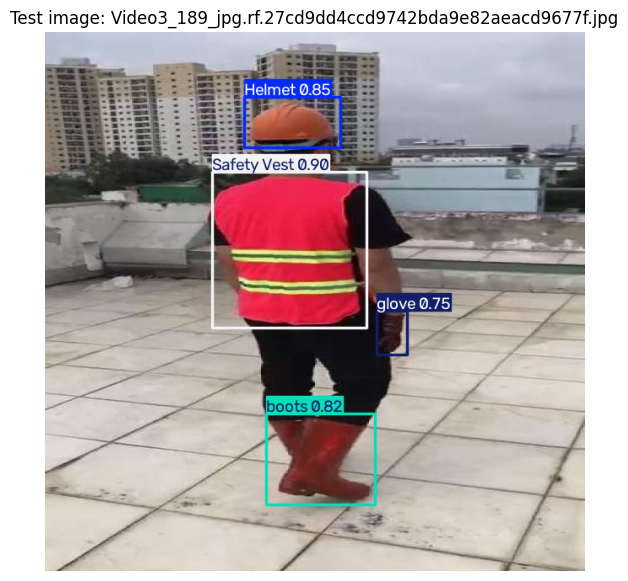

Class: Safety Vest, Confidence: 0.896, Box (xyxy): [      198.1       166.4       381.4       351.5]
Class: Helmet, Confidence: 0.848, Box (xyxy): [      236.5        77.3       350.5       137.8]
Class: boots, Confidence: 0.821, Box (xyxy): [      262.5       453.6         392       561.4]
Class: glove, Confidence: 0.754, Box (xyxy): [      393.5       331.4       429.2       383.5]


In [11]:
# Select an image from the held-out test set.
from pathlib import Path
import cv2
import matplotlib.pyplot as plt

# Correct path to the test images folder
test_images_dir = Path("/content/ppe_data/Dataset_no_person_glasses/test/images")

# Find supported image files in the test directory.
test_image_paths = [
    p for p in test_images_dir.iterdir()
    if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
]

# Stop if the test image directory is empty.
if not test_image_paths:
    raise FileNotFoundError(
        "No test images found. Check the path in your dataset configuration."
    )

# Run prediction on the first test image.
sample_path = str(test_image_paths[0])
sample_result = model.predict(
    source=sample_path,
    conf=0.25,
    imgsz=640,
    device="cpu",
    verbose=False
)[0]

# Convert the annotated BGR image to RGB for notebook display.
sample_annotated = sample_result.plot()

plt.figure(figsize=(11, 7))
plt.imshow(cv2.cvtColor(sample_annotated, cv2.COLOR_BGR2RGB))
plt.title(f"Test image: {Path(sample_path).name}")
plt.axis("off")
plt.show()

# Print predicted classes, confidence scores, and box coordinates.
for box in sample_result.boxes:
    class_id = int(box.cls.item())
    confidence = float(box.conf.item())
    xyxy = box.xyxy[0].cpu().numpy().round(1)

    # Fixed best_model -> model
    print(
        f"Class: {model.names[class_id]}, "
        f"Confidence: {confidence:.3f}, "
        f"Box (xyxy): {xyxy}"
    )